# Phase 5: Supervised Baseline Models

This notebook trains and compares supervised baseline models for credit card
fraud detection.

The objectives are to:

- Load the training and validation splits created in Phase 3.
- Apply the selected Phase 4 feature-engineering configuration.
- Train Logistic Regression, Random Forest, and LightGBM baseline models.
- Evaluate each model on the validation set.
- Compare precision, recall, F1-score, PR-AUC, ROC-AUC, and false-positive
  behavior.
- Save trained baseline artifacts and validation metrics.
- Update the model-comparison report.

The untouched test set is not used for model training, model selection,
threshold tuning, or evaluation in this notebook.

In [1]:
import json
import logging
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## Imports and configuration

This cell imports the libraries required for data handling, supervised
modeling, evaluation, and visualization.

It defines:

- Paths to the processed training and validation datasets.
- Output directories for figures, reports, and baseline model artifacts.
- A fixed random seed of `42`.
- An initial decision threshold of `0.5`.
- The selected feature configuration: `log_amount_and_time_hours`.

The `0.5` threshold is a baseline operating point, not an optimized threshold.
Threshold optimization is performed later using validation data only.

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
BASELINE_MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "baseline_models"

RANDOM_SEED = 42
DEFAULT_THRESHOLD = 0.5
FEATURE_CONFIGURATION = "log_amount_and_time_hours"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_MODELS_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Selected feature configuration: %s", FEATURE_CONFIGURATION)

2026-11-01 10:02:34,355 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 10:02:34,357 | INFO | Selected feature configuration: log_amount_and_time_hours


## Load training and validation splits

This cell loads the training and validation feature matrices and target vectors
created during Phase 3.

It verifies that:

- Both feature and target files exist.
- Neither split is empty.
- Feature and target row counts match.
- The number of fraudulent transactions is recorded for each split.

Only training and validation data are loaded. The test set remains untouched.

In [3]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


X_train, y_train = load_split(
    feature_path=DATA_PROCESSED_DIR / "train" / "X_train.parquet",
    target_path=DATA_PROCESSED_DIR / "train" / "y_train.parquet",
)

X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

logger.info("Training features: %s", X_train.shape)
logger.info("Validation features: %s", X_validation.shape)
logger.info("Training fraud count: %s", int(y_train.sum()))
logger.info("Validation fraud count: %s", int(y_validation.sum()))

2026-11-01 10:02:42,928 | INFO | Training features: (198608, 30)
2026-11-01 10:02:42,929 | INFO | Validation features: (42559, 30)
2026-11-01 10:02:42,930 | INFO | Training fraud count: 331
2026-11-01 10:02:42,931 | INFO | Validation fraud count: 71


## Apply the selected feature configuration

This cell applies the feature-engineering configuration selected in Phase 4:

```text
log_amount_and_time_hours
```

It adds:

- `Amount_log1p`: a zero-safe logarithmic transformation of `Amount`.
- `Time_hours`: elapsed transaction time converted from seconds to hours.

The same transformation is applied independently to the training and
validation sets. The cell also verifies that both datasets have identical
feature columns and that the `Class` target column is not present in the
feature matrices.

In [4]:
def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


def apply_selected_feature_configuration(
    features: pd.DataFrame,
    configuration_name: str,
) -> pd.DataFrame:
    """Apply the selected Phase 4 feature-engineering configuration."""
    if configuration_name != "log_amount_and_time_hours":
        raise ValueError(
            "This notebook expects the selected Phase 4 configuration: "
            "'log_amount_and_time_hours'."
        )

    transformed = add_log_amount_feature(features)
    transformed = add_elapsed_time_hours_feature(transformed)

    if "Class" in transformed.columns:
        raise ValueError("Target leakage detected in engineered features.")

    return transformed


X_train_engineered = apply_selected_feature_configuration(
    features=X_train,
    configuration_name=FEATURE_CONFIGURATION,
)

X_validation_engineered = apply_selected_feature_configuration(
    features=X_validation,
    configuration_name=FEATURE_CONFIGURATION,
)

if list(X_train_engineered.columns) != list(X_validation_engineered.columns):
    raise ValueError("Training and validation feature columns do not match.")

logger.info("Engineered training features: %s", X_train_engineered.shape)
logger.info("Engineered validation features: %s", X_validation_engineered.shape)
logger.info(
    "Engineered feature columns: %s",
    list(X_train_engineered.columns),
)

2026-11-01 10:02:49,624 | INFO | Engineered training features: (198608, 32)
2026-11-01 10:02:49,625 | INFO | Engineered validation features: (42559, 32)
2026-11-01 10:02:49,626 | INFO | Engineered feature columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Amount_log1p', 'Time_hours']


## Define evaluation metrics

This cell defines an evaluation function using metrics appropriate for highly
imbalanced fraud detection.

For each model, it calculates:

- Precision.
- Recall.
- F1-score.
- PR-AUC.
- ROC-AUC.
- False-positive rate.
- True positives, false positives, true negatives, and false negatives.
- Number of transactions flagged.

PR-AUC is particularly important because fraudulent transactions are extremely
rare. Accuracy alone would be misleading because a model could achieve high
accuracy by predicting nearly every transaction as legitimate.

In [5]:
def evaluate_classification_predictions(
    y_true: pd.Series,
    y_pred: np.ndarray,
    y_score: np.ndarray,
    threshold: float,
) -> dict:
    """Calculate metrics appropriate for highly imbalanced fraud detection."""
    confusion = confusion_matrix(y_true, y_pred, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    false_positive_rate = (
        false_positive / (false_positive + true_negative)
        if (false_positive + true_negative) > 0
        else 0.0
    )

    has_both_classes = len(np.unique(y_true)) > 1

    return {
        "threshold": threshold,
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1),
        "pr_auc": (
            float(average_precision_score(y_true, y_score))
            if has_both_classes
            else np.nan
        ),
        "roc_auc": (
            float(roc_auc_score(y_true, y_score))
            if has_both_classes
            else np.nan
        ),
        "false_positive_rate": float(false_positive_rate),
        "true_positives": int(true_positive),
        "false_positives": int(false_positive),
        "true_negatives": int(true_negative),
        "false_negatives": int(false_negative),
        "transactions_flagged": int(true_positive + false_positive),
    }

## Define supervised baseline models

This cell defines three supervised baseline models:

1. **Logistic Regression**: uses `StandardScaler`, which is fitted only on
   training data.
2. **Random Forest**: does not require feature scaling.
3. **LightGBM**: does not require feature scaling.

These are baseline configurations. Hyperparameter optimization, class
weighting, and resampling strategies are investigated in later phases.

In [6]:
def create_logistic_regression_pipeline() -> Pipeline:
    """Create a scaled Logistic Regression baseline pipeline."""
    return Pipeline(
        steps=[
            ("standard_scaler", StandardScaler()),
            (
                "logistic_regression",
                LogisticRegression(
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                    solver="lbfgs",
                ),
            ),
        ]
    )


def create_random_forest_pipeline() -> Pipeline:
    """Create an unscaled Random Forest baseline pipeline."""
    return Pipeline(
        steps=[
            (
                "random_forest",
                RandomForestClassifier(
                    n_estimators=200,
                    max_depth=None,
                    min_samples_leaf=2,
                    n_jobs=-1,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


def create_lightgbm_pipeline() -> Pipeline:
    """Create an unscaled LightGBM baseline pipeline."""
    return Pipeline(
        steps=[
            (
                "lightgbm",
                LGBMClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    num_leaves=31,
                    max_depth=-1,
                    min_child_samples=20,
                    random_state=RANDOM_SEED,
                    n_jobs=-1,
                    verbose=-1,
                ),
            ),
        ]
    )


BASELINE_MODEL_FACTORIES = {
    "Logistic Regression": create_logistic_regression_pipeline,
    "Random Forest": create_random_forest_pipeline,
    "LightGBM": create_lightgbm_pipeline,
}

BASELINE_PREPROCESSING = {
    "Logistic Regression": "StandardScaler fitted on training data only",
    "Random Forest": "No scaling required",
    "LightGBM": "No scaling required",
}

logger.info("Baseline model factories defined: %s", list(BASELINE_MODEL_FACTORIES))

2026-11-01 10:03:05,215 | INFO | Baseline model factories defined: ['Logistic Regression', 'Random Forest', 'LightGBM']


## Train and evaluate baseline models

This cell trains each supervised baseline model on the engineered training
data and evaluates it on the validation set.

All models use:

- The same training data.
- The same validation data.
- The same feature configuration.
- The same initial decision threshold of `0.5`.

The results table compares precision, recall, F1-score, PR-AUC, ROC-AUC,
false-positive rate, flagged transactions, false positives, false negatives,
and training duration.

These are validation results, not final estimates of real-world performance.

In [7]:
def train_and_evaluate_baseline(
    model_name: str,
    pipeline: Pipeline,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_validation: pd.DataFrame,
    y_validation: pd.Series,
) -> tuple[dict, Pipeline, np.ndarray]:
    """Train one baseline model and evaluate it on validation data."""
    training_start_time = time.time()
    pipeline.fit(X_train, y_train)
    training_duration = time.time() - training_start_time

    validation_scores = pipeline.predict_proba(X_validation)[:, 1]
    validation_predictions = (validation_scores >= DEFAULT_THRESHOLD).astype(int)

    metrics = evaluate_classification_predictions(
        y_true=y_validation,
        y_pred=validation_predictions,
        y_score=validation_scores,
        threshold=DEFAULT_THRESHOLD,
    )

    metrics.update(
        {
            "model": model_name,
            "feature_configuration": FEATURE_CONFIGURATION,
            "imbalance_strategy": "None",
            "preprocessing": BASELINE_PREPROCESSING[model_name],
            "training_duration_seconds": training_duration,
            "feature_count": X_train.shape[1],
        }
    )

    return metrics, pipeline, validation_scores


baseline_results = []
trained_baseline_pipelines = {}
validation_scores_by_model = {}

for model_name, model_factory in BASELINE_MODEL_FACTORIES.items():
    logger.info("Training baseline model: %s", model_name)

    result, pipeline, validation_scores = train_and_evaluate_baseline(
        model_name=model_name,
        pipeline=model_factory(),
        X_train=X_train_engineered,
        y_train=y_train,
        X_validation=X_validation_engineered,
        y_validation=y_validation,
    )

    baseline_results.append(result)
    trained_baseline_pipelines[model_name] = pipeline
    validation_scores_by_model[model_name] = validation_scores

baseline_results_dataframe = pd.DataFrame(baseline_results)

baseline_results_dataframe[
    [
        "model",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
        "training_duration_seconds",
    ]
]

2026-11-01 10:03:14,559 | INFO | Training baseline model: Logistic Regression
2026-11-01 10:03:15,909 | INFO | Training baseline model: Random Forest
2026-11-01 10:05:20,759 | INFO | Training baseline model: LightGBM


,model,precision,recall,f1_score,pr_auc,roc_auc,false_positive_rate,transactions_flagged,false_positives,false_negatives,training_duration_seconds
0,Logistic Regression,0.837209,0.507042,0.631579,0.693844,0.961380,0.000165,43,7,35,1.233808
1,Random Forest,0.981481,0.746479,0.848000,0.821747,0.945541,0.000024,54,1,18,124.479026
2,LightGBM,0.273381,0.535211,0.361905,0.347774,0.701455,0.002377,139,101,33,5.789343


## Confusion matrices by model

This cell creates a confusion matrix for each baseline model at the initial
decision threshold of `0.5`.

Each matrix shows:

- True negatives.
- False positives.
- False negatives.
- True positives.

False positives are legitimate transactions incorrectly flagged for review.
False negatives are fraudulent transactions missed by the model. Both error
types matter, but they have different operational costs.

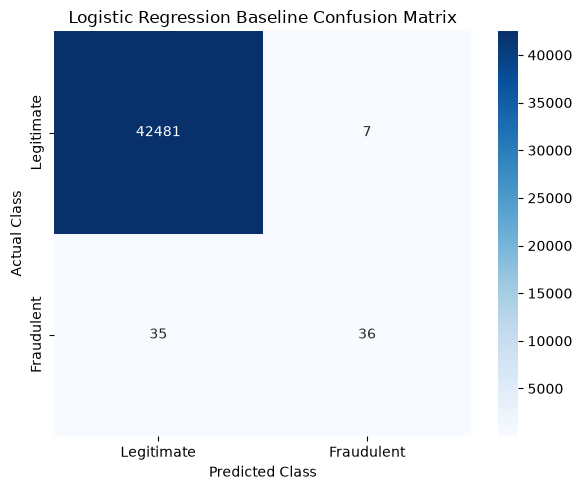

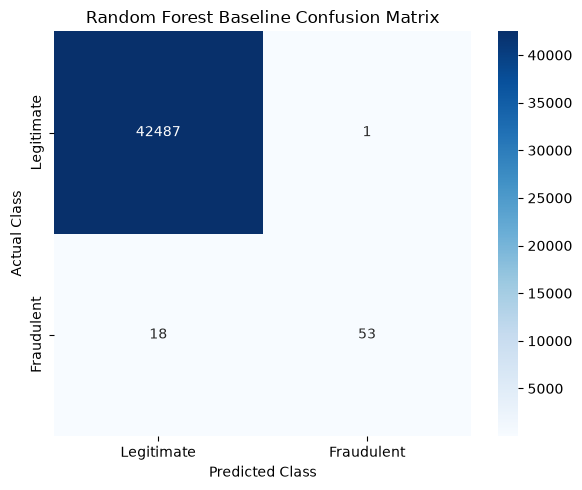

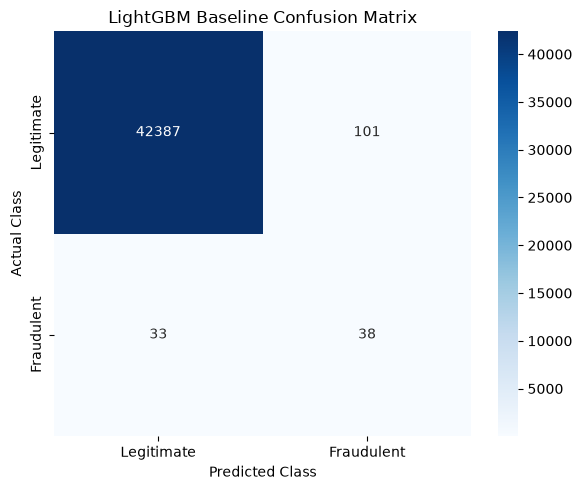

2026-11-01 10:05:29,813 | INFO | Baseline confusion matrices generated.


In [8]:
def plot_confusion_matrix(
    y_true: pd.Series,
    y_score: np.ndarray,
    threshold: float,
    title: str,
    output_path: Path,
) -> None:
    """Plot a confusion matrix for a configured decision threshold."""
    predictions = (y_score >= threshold).astype(int)
    confusion = confusion_matrix(y_true, predictions, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraudulent"],
        yticklabels=["Legitimate", "Fraudulent"],
    )
    plt.title(title)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


for model_name, validation_scores in validation_scores_by_model.items():
    safe_model_name = model_name.lower().replace(" ", "_")

    plot_confusion_matrix(
        y_true=y_validation,
        y_score=validation_scores,
        threshold=DEFAULT_THRESHOLD,
        title=f"{model_name} Baseline Confusion Matrix",
        output_path=FIGURES_DIR / f"{safe_model_name}_baseline_confusion_matrix.png",
    )

logger.info("Baseline confusion matrices generated.")

## Precision-recall and ROC curves

This cell plots validation precision-recall and ROC curves for all supervised
baseline models.

The precision-recall curve is especially useful for highly imbalanced
classification because it focuses on performance for the minority fraud class.

The ROC curve shows the trade-off between true-positive rate and false-positive
rate across thresholds. A random classifier would follow the diagonal line.

These curves describe ranking performance across thresholds; they do not
replace evaluation at a specific operational threshold.

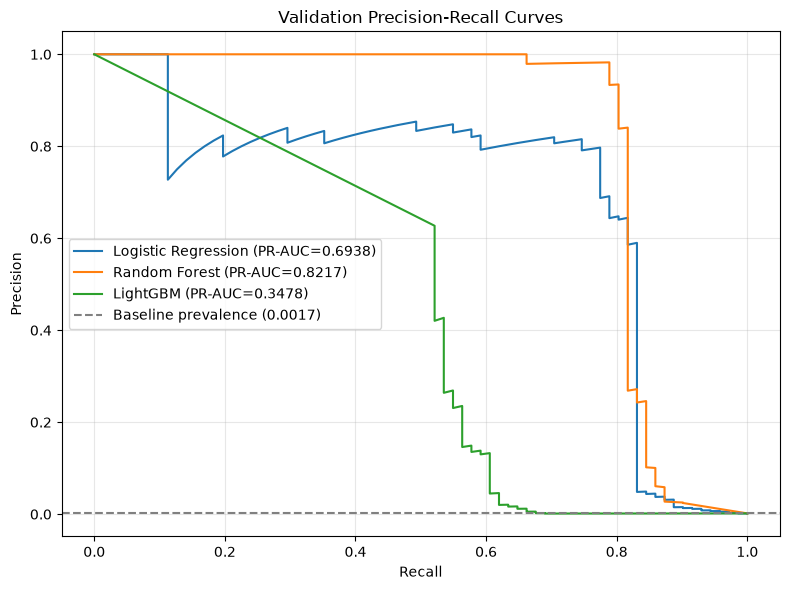

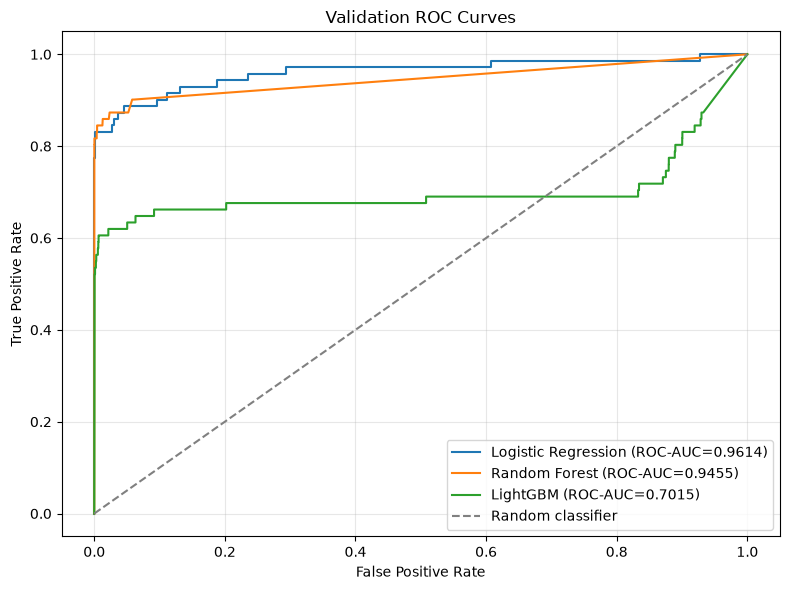

2026-11-01 10:05:34,158 | INFO | Supervised baseline PR and ROC curves generated.


In [9]:
def plot_precision_recall_curves(
    y_true: pd.Series,
    scores_by_model: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation precision-recall curves for all baseline models."""
    plt.figure(figsize=(8, 6))

    for model_name, scores in scores_by_model.items():
        precision_values, recall_values, _ = precision_recall_curve(
            y_true,
            scores,
        )
        pr_auc = average_precision_score(y_true, scores)

        plt.plot(
            recall_values,
            precision_values,
            label=f"{model_name} (PR-AUC={pr_auc:.4f})",
        )

    fraud_prevalence = y_true.mean()
    plt.axhline(
        fraud_prevalence,
        color="gray",
        linestyle="--",
        label=f"Baseline prevalence ({fraud_prevalence:.4f})",
    )

    plt.title("Validation Precision-Recall Curves")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_roc_curves(
    y_true: pd.Series,
    scores_by_model: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation ROC curves for all baseline models."""
    plt.figure(figsize=(8, 6))

    for model_name, scores in scores_by_model.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            scores,
        )
        roc_auc = roc_auc_score(y_true, scores)

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{model_name} (ROC-AUC={roc_auc:.4f})",
        )

    plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")

    plt.title("Validation ROC Curves")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


supervised_pr_figure_path = FIGURES_DIR / "supervised_baseline_precision_recall_curves.png"
supervised_roc_figure_path = FIGURES_DIR / "supervised_baseline_roc_curves.png"

plot_precision_recall_curves(
    y_true=y_validation,
    scores_by_model=validation_scores_by_model,
    output_path=supervised_pr_figure_path,
)

plot_roc_curves(
    y_true=y_validation,
    scores_by_model=validation_scores_by_model,
    output_path=supervised_roc_figure_path,
)

logger.info("Supervised baseline PR and ROC curves generated.")

## Save baseline model artifacts

This cell saves each trained baseline model and its metadata.

For every model, the following artifacts are saved:

- Trained model pipeline.
- Feature configuration.
- Feature columns.
- Target column.
- Decision threshold.
- Imbalance strategy.
- Random seed.
- Preprocessing description.
- Validation metrics.

Each artifact is clearly marked as a Phase 5 baseline, not the final production
model.

In [10]:
def save_baseline_model_artifacts(
    model_name: str,
    pipeline: Pipeline,
    metrics: dict,
    output_directory: Path,
) -> dict:
    """Save one trained baseline model and its metadata."""
    safe_model_name = model_name.lower().replace(" ", "_")
    model_directory = output_directory / safe_model_name
    model_directory.mkdir(parents=True, exist_ok=True)

    model_path = model_directory / "model.joblib"
    metadata_path = model_directory / "metadata.json"

    joblib.dump(pipeline, model_path)

    metadata = {
        "model_name": model_name,
        "model_type": "supervised_baseline_classifier",
        "feature_configuration": FEATURE_CONFIGURATION,
        "feature_columns": list(X_train_engineered.columns),
        "target_column": "Class",
        "decision_threshold": DEFAULT_THRESHOLD,
        "imbalance_strategy": "None",
        "random_seed": RANDOM_SEED,
        "preprocessing": BASELINE_PREPROCESSING[model_name],
        "validation_metrics": metrics,
        "artifact_note": (
            "This is a Phase 5 baseline artifact, not the final production model."
        ),
    }

    with metadata_path.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2, default=str)

    return {
        "model_path": str(model_path),
        "metadata_path": str(metadata_path),
    }


baseline_artifact_paths = {}

for model_name, pipeline in trained_baseline_pipelines.items():
    matching_result = baseline_results_dataframe[
        baseline_results_dataframe["model"] == model_name
    ].iloc[0].to_dict()

    baseline_artifact_paths[model_name] = save_baseline_model_artifacts(
        model_name=model_name,
        pipeline=pipeline,
        metrics=matching_result,
        output_directory=BASELINE_MODELS_DIR,
    )

    logger.info(
        "Saved baseline artifacts for %s: %s",
        model_name,
        baseline_artifact_paths[model_name],
    )

2026-11-01 10:06:01,761 | INFO | Saved baseline artifacts for Logistic Regression: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_models\\logistic_regression\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_models\\logistic_regression\\metadata.json'}
2026-11-01 10:06:02,066 | INFO | Saved baseline artifacts for Random Forest: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_models\\random_forest\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_models\\random_forest\\metadata.json'}
2026-11-01 10:06:02,248 | INFO | Saved baseline artifacts for LightGBM: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_models\\lightgbm\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection

## Update the model-comparison report

This cell appends the Phase 5 supervised baseline results to the existing
model-comparison CSV created in Phase 4.

The combined report allows baseline and later experiments to be compared using
a consistent format. It preserves prior Phase 4 results and adds the Logistic
Regression, Random Forest, and LightGBM baseline results from this notebook.

In [11]:
def update_model_comparison_report(
    phase5_results: pd.DataFrame,
    comparison_path: Path,
) -> pd.DataFrame:
    """Append Phase 5 baseline results to the existing comparison report."""
    if comparison_path.exists():
        existing_results = pd.read_csv(comparison_path)
    else:
        existing_results = pd.DataFrame()

    phase5_columns = list(phase5_results.columns)

    if not existing_results.empty:
        missing_columns = set(phase5_columns) - set(existing_results.columns)
        for column in missing_columns:
            existing_results[column] = np.nan

    combined_results = pd.concat(
        [existing_results[phase5_columns], phase5_results[phase5_columns]],
        ignore_index=True,
    )

    combined_results.to_csv(comparison_path, index=False)
    return combined_results


model_comparison_path = REPORTS_DIR / "model_comparison.csv"

updated_model_comparison = update_model_comparison_report(
    phase5_results=baseline_results_dataframe,
    comparison_path=model_comparison_path,
)

logger.info(
    "Updated model comparison report: %s rows",
    len(updated_model_comparison),
)

2026-11-01 10:06:08,224 | INFO | Updated model comparison report: 6 rows


## Write supervised baseline report

This cell creates a Markdown report summarizing the supervised baseline
results.

The report includes:

- Feature configuration.
- Evaluation dataset.
- Decision threshold.
- Imbalance strategy.
- Validation metrics for each model.
- Confusion-matrix components.
- Training duration.
- Preprocessing method.
- Interpretation and limitations.

The report clearly states that these are validation results and that the test
set remains reserved for final evaluation.

In [12]:
def write_supervised_baseline_report(
    results_dataframe: pd.DataFrame,
    report_path: Path,
) -> None:
    """Write a concise supervised baseline evaluation report."""
    report_lines = [
        "# Supervised Baseline Model Results",
        "",
        "## Scope",
        "",
        f"- Feature configuration: `{FEATURE_CONFIGURATION}`",
        "- Evaluation dataset: Validation set",
        f"- Decision threshold: {DEFAULT_THRESHOLD}",
        "- Imbalance strategy: None",
        "- Test set: Not used in this phase",
        "",
        "## Validation Results",
        "",
    ]

    for _, row in results_dataframe.iterrows():
        report_lines.extend(
            [
                f"### {row['model']}",
                "",
                f"- Precision: {row['precision']:.4f}",
                f"- Recall: {row['recall']:.4f}",
                f"- F1-score: {row['f1_score']:.4f}",
                f"- PR-AUC: {row['pr_auc']:.4f}",
                f"- ROC-AUC: {row['roc_auc']:.4f}",
                f"- False-positive rate: {row['false_positive_rate']:.6f}",
                f"- Transactions flagged: {row['transactions_flagged']:,}",
                f"- True positives: {row['true_positives']}",
                f"- False positives: {row['false_positives']:,}",
                f"- False negatives: {row['false_negatives']}",
                f"- Training duration: {row['training_duration_seconds']:.2f} seconds",
                f"- Preprocessing: {row['preprocessing']}",
                "",
            ]
        )

    report_lines.extend(
        [
            "## Interpretation",
            "",
            "- These are validation results, not final generalization estimates.",
            "- PR-AUC is the primary ranking metric because fraud is extremely rare.",
            "- A model with higher recall may produce more false positives.",
            "- Class weighting and resampling will be investigated in the next notebook.",
            "- The untouched test set remains reserved for final evaluation.",
        ]
    )

    report_path.write_text("\n".join(report_lines), encoding="utf-8")


supervised_baseline_report_path = REPORTS_DIR / "supervised_baseline_report.md"

write_supervised_baseline_report(
    results_dataframe=baseline_results_dataframe,
    report_path=supervised_baseline_report_path,
)

logger.info(
    "Supervised baseline report saved to: %s",
    supervised_baseline_report_path,
)

2026-11-01 10:06:17,872 | INFO | Supervised baseline report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\supervised_baseline_report.md


## Validate Phase 5 baseline artifacts

This final cell verifies that all required Phase 5 baseline outputs were
created:

- Precision-recall curve figure.
- ROC curve figure.
- Supervised baseline report.
- Updated model-comparison CSV.
- Trained model artifact for each baseline model.
- Metadata file for each baseline model.

If any required artifact is missing, the notebook raises an error instead of
silently claiming successful completion.

At this point, the supervised baseline phase is complete. The results provide
a reference point for the next phase, which investigates class-imbalance
strategies such as class weighting and resampling.

In [13]:
required_baseline_artifacts = [
    supervised_pr_figure_path,
    supervised_roc_figure_path,
    supervised_baseline_report_path,
    model_comparison_path,
]

for artifact_paths in baseline_artifact_paths.values():
    required_baseline_artifacts.extend(
        [
            Path(artifact_paths["model_path"]),
            Path(artifact_paths["metadata_path"]),
        ]
    )

missing_artifacts = [
    path for path in required_baseline_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing Phase 5 baseline artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required Phase 5 baseline artifacts were generated successfully.")
print("Phase 5 supervised baseline modelling completed successfully.")

2026-11-01 10:06:29,462 | INFO | All required Phase 5 baseline artifacts were generated successfully.


Phase 5 supervised baseline modelling completed successfully.
